In [14]:
#photo to be used is "C:\Users\SMAYA\Desktop\dp.jpg"\
import cv2
import numpy as np

In [15]:
dp = cv2.imread("C:\\Users\\SMAYA\\Desktop\\dp.jpg")
print(dp.shape)

dp_median = cv2.medianBlur(dp, 5) # Used to remove salt and pepper noise
cv2.imshow("Median Filtered Image", dp_median)
cv2.waitKey(5000)
dp_gaussian = cv2.GaussianBlur(dp, (5, 5), 0)# Used to remove Gaussian noise Parameters: (5, 5) is the kernel size and 0 is the standard deviation in X and Y direction
#Understand significance of standard deviation in Gaussian filter. It controls the amount of smoothing. A larger standard deviation results in more blurring, while a smaller standard deviation preserves more details in the image.
cv2.imshow("Gaussian Filtered Image : std=0", dp_gaussian)
cv2.waitKey(5000)
dp_gaussian = cv2.GaussianBlur(dp, (5, 5), 10) # Used to remove Gaussian noise Parameters: (5, 5) is the kernel size and 10 is the standard deviation in X and Y direction
cv2.imshow("Gaussian Filtered Image : std=10", dp_gaussian)
cv2.waitKey(5000)
cv2.destroyAllWindows()

(640, 640, 3)


In [16]:
dp_gradient = cv2.Laplacian(dp, cv2.CV_64F)
#dp_gradient = np.uint8(np.absolute(dp_gradient))
cv2.imshow("Gradient Image", dp_gradient)
cv2.waitKey(5000)
dp_gradient_abs = np.uint8(np.absolute(dp_gradient))
cv2.imshow("Absolute Gradient Image", dp_gradient_abs)
cv2.waitKey(5000)
cv2.destroyAllWindows()

In [17]:
import cv2
import numpy as np
from skimage import filters, feature
image_path = r"C:\Users\SMAYA\Desktop\dc\trial_image_1.webp"

def apply_laplacian_and_unsharp(image_path):
    # Load image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    img_float = img.astype(np.float64)
    cv2.imshow("Original Image", img)
    cv2.waitKey(2000)
    cv2.imshow("Image float 64", img_float.astype(np.uint8))
    cv2.waitKey(2000)

    # 1. Discrete Laplacian Filtering (8-neighbor kernel via filter2D)
    kernel_laplacian = np.array([[1,  1, 1],
                                 [1, -8, 1],
                                 [1,  1, 1]], dtype=np.float64)
    laplacian_response = cv2.filter2D(img_float, -1, kernel_laplacian)
    cv2.imshow("Laplacian Response", np.clip(laplacian_response, 0, 255).astype(np.uint8))
    cv2.waitKey(2000)

    # Sharpen image: Subtracting negative-center Laplacian
    img_sharpened_laplacian = np.clip(img_float - laplacian_response, 0, 255).astype(np.uint8)
    cv2.imshow("Sharpened Image (Laplacian)", img_sharpened_laplacian)
    cv2.waitKey(2000)

    # 2. Unsharp Masking & High-Boost Filtering
    blurred = cv2.GaussianBlur(img_float, (5, 5), sigmaX=1.0)
    unsharp_mask = img_float - blurred
    
    k_unsharp = 1.0
    k_highboost = 2.5
    
    img_unsharp = np.clip(img_float + k_unsharp * unsharp_mask, 0, 255).astype(np.uint8)
    cv2.imshow("Unsharp Masked Image", img_unsharp)
    cv2.waitKey(2000)

    img_highboost = np.clip(img_float + k_highboost * unsharp_mask, 0, 255).astype(np.uint8)
    cv2.imshow("High-Boost Filtered Image", img_highboost)
    cv2.waitKey(2000)

    # --- SCIKIT-IMAGE IMPLEMENTATION ---
    # Laplacian using skimage filters
    sk_laplacian = filters.laplace(img / 255.0)
    sk_sharpened = np.clip((img / 255.0) - sk_laplacian, 0.0, 1.0) * 255.0
    cv2.imshow("Sharpened Image (Scikit-Image)", sk_sharpened.astype(np.uint8))
    cv2.waitKey(2000)
    cv2.destroyAllWindows()
    return img_sharpened_laplacian, img_unsharp, img_highboost, sk_sharpened.astype(np.uint8)

t1,t2,t3,t4 = apply_laplacian_and_unsharp(image_path)

In [18]:
import cv2
import numpy as np

img = cv2.imread('C:\\Users\\SMAYA\\Desktop\\dp.jpg')

# Mean Filter (Averaging)
mean_blur = cv2.blur(img, (5, 5))

# Gaussian Filter (sigmaX=0 calculates it automatically from kernel size)
gaussian_blur = cv2.GaussianBlur(img, (5, 5), 0)

# Median Filter (Kernel size must be odd)
median_blur = cv2.medianBlur(img, 5)

In [19]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Gradients (Sobel)
grad_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
grad_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
gradient_magnitude = cv2.magnitude(grad_x, grad_y)

# Laplacian
laplacian = cv2.Laplacian(gray, cv2.CV_64F)

# Laplacian of Gaussian (LoG)
blurred_gray = cv2.GaussianBlur(gray, (5, 5), 0)
log_img = cv2.Laplacian(blurred_gray, cv2.CV_64F)

# Canny Edge Detection
edges = cv2.Canny(gray, threshold1=100, threshold2=200)

# Harris Corner Detection
gray_float = np.float32(gray)
corners = cv2.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
# Dilate to make corners visible, then mark them on the original image
img_corners = img.copy()
img_corners[cv2.dilate(corners, None) > 0.01 * corners.max()] = [0, 0, 255]

In [20]:
cv2.imshow('Mean Filter', mean_blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [21]:
cv2.imshow('Gaussian Filter', gaussian_blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [22]:
cv2.imshow('Median Filter', median_blur)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [23]:
cv2.imshow('Gradient Magnitude', gradient_magnitude)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [24]:
cv2.imshow('Laplacian', laplacian)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [25]:
cv2.imshow('LoG', log_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [26]:
cv2.imshow('Canny Edges', edges)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [27]:
cv2.imshow('Harris Corners', img_corners)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [28]:
#Haugh Transform for line detection
# Detect lines on the Canny edges from the previous step
# Probabilistic Hough Transform is faster and returns line segments (x1, y1, x2, y2)
lines = cv2.HoughLinesP(edges, rho=1, theta=np.pi/180, threshold=50, minLineLength=50, maxLineGap=10)

img_lines = img.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        cv2.line(img_lines, (x1, y1), (x2, y2), (0, 255, 0), 2)
cv2.imshow('Hough Lines', img_lines)
cv2.waitKey(1000)
cv2.destroyAllWindows()

In [29]:
# Difference between two images (must be same size)
img1 = cv2.imread('C:\\Users\\SMAYA\\Desktop\\dp.jpg')
img2 = cv2.imread('C:\\Users\\SMAYA\\Desktop\\dp_clahe.jpg')
diff = cv2.absdiff(img1, img2)
cv2.imshow('Difference Image', diff)
cv2.waitKey(0)
# Rotate Image (e.g., 45 degrees, 90 degrees)
(h, w) = img.shape[:2]
center = (w // 2, h // 2)

# 45 degrees
M_45 = cv2.getRotationMatrix2D(center, 45, scale=1.0)
rotated_45 = cv2.warpAffine(img, M_45, (w, h))
cv2.imshow('Rotated Image 45 degrees', rotated_45)
cv2.waitKey(0)
# 90 degrees
M_90 = cv2.getRotationMatrix2D(center, 90, scale=1.0)
rotated_90 = cv2.warpAffine(img, M_90, (w, h))
cv2.imshow('Rotated Image 90 degrees', rotated_90)
cv2.waitKey(0)

-1

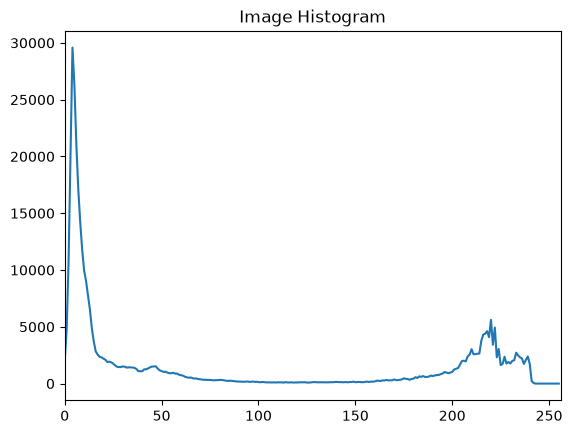

AttributeError: 'NoneType' object has no attribute 'flatten'